# 04 — Predicting Bad Reviews at Delivery Time

**CRISP-DM phases:** Modeling → Evaluation

**Business problem:** 1–2 star reviews hurt Olist's reputation and conversion. If we can flag orders likely to receive a bad review **right after delivery**, the customer-service team can contact those customers first (apology, voucher, fast resolution) *before* they write the review.

**Design decisions (to avoid data leakage)**
| Decision | Choice |
|---|---|
| Target | `is_bad_review` = review score 1 or 2 |
| Prediction moment | Right after delivery |
| Rows | Only reviews written on/after the delivery day (if a review already exists, there is nothing to predict) |
| Features | Only information known at delivery (no review text, no review date) |
| Seller history | Bad-review rate computed only from reviews **available before** each delivery |
| Split | **Time-based**: train Jan 2017–Feb 2018, validate Mar–Apr 2018, test May–Aug 2018 |
| Metrics | PR-AUC and top-10% precision / recall / lift — accuracy is misleading with ~10% positives |

Feature engineering lives in `src/features.py`.

In [1]:
import sys
import warnings
from pathlib import Path

import joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import shap
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, confusion_matrix,
                             f1_score, precision_recall_curve, precision_score,
                             recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
from features import BOOL_FEATURES, CATEGORICAL_FEATURES, FEATURES, NUMERIC_FEATURES, TARGET, build_features

# LightGBM 4.7 deprecates eval_set and shap warns about an output format change;
# neither affects the results, so we hide them to keep the notebook readable.
warnings.filterwarnings("ignore", message=".*eval_set.*")
warnings.filterwarnings("ignore", message=".*TreeExplainer shap values output.*")

FIG_DIR = PROJECT_ROOT / "reports" / "figures"
DATA_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(exist_ok=True)

GREY, RED, BLUE, DARK, GREEN, SAND = "#B0B7BF", "#D1495B", "#2E86AB", "#2B2D42", "#81B29A", "#F2CC8F"
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titleweight": "bold",
    "axes.titlesize": 13,
    "axes.titlelocation": "left",
    "font.size": 10,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


orders = pd.read_parquet(DATA_DIR / "orders.parquet")
df = build_features(orders)
print(f"Modelling rows: {len(df):,} | bad-review rate: {df[TARGET].mean():.1%}")

Modelling rows: 90,590 | bad-review rate: 9.5%


## 1. Time-based split

We train on the past and evaluate on the future, exactly as the model would be used. A random split would mix months and give optimistic results (e.g. the model could learn a seller's behaviour from orders that happen *after* the test orders).

In [2]:
train = df[df["purchase_ts"] < "2018-03-01"]
valid = df[(df["purchase_ts"] >= "2018-03-01") & (df["purchase_ts"] < "2018-05-01")]
test = df[df["purchase_ts"] >= "2018-05-01"]

X_train, y_train = train[FEATURES], train[TARGET].to_numpy()
X_valid, y_valid = valid[FEATURES], valid[TARGET].to_numpy()
X_test, y_test = test[FEATURES], test[TARGET].to_numpy()

pd.DataFrame({
    "rows": [len(train), len(valid), len(test)],
    "bad_review_rate": [y_train.mean(), y_valid.mean(), y_test.mean()],
    "from": [train["purchase_ts"].min().date(), valid["purchase_ts"].min().date(), test["purchase_ts"].min().date()],
    "to": [train["purchase_ts"].max().date(), valid["purchase_ts"].max().date(), test["purchase_ts"].max().date()],
}, index=["train", "valid", "test"]).round(3)

,rows,bad_review_rate,from,to
train,53606,0.098,2017-01-05,2018-02-28
valid,12451,0.104,2018-03-01,2018-04-30
test,24533,0.085,2018-05-01,2018-08-29


## 2. Evaluation helpers

- **PR-AUC (average precision)**: area under the precision–recall curve. A random model scores ≈ the positive rate (~0.09), so that is the bar to beat.
- **ROC-AUC**: probability that a random bad-review order gets a higher score than a random good one (0.5 = random).
- **Top-10% metrics** (the business view): if customer service can only contact 10% of delivered orders, how many of the contacted orders are truly at risk (**precision**), what share of all bad reviews they reach (**recall**), and how much better than random that is (**lift**).

In [3]:
def top_k(y, proba, frac=0.10):
    n = int(len(y) * frac)
    top = np.argsort(-proba)[:n]
    precision = y[top].mean()
    return {"precision@10%": precision, "recall@10%": y[top].sum() / y.sum(), "lift@10%": precision / y.mean()}


def evaluate(name, y, proba):
    return {
        "model": name,
        "accuracy@0.5": accuracy_score(y, proba >= 0.5),
        "ROC-AUC": roc_auc_score(y, proba),
        "PR-AUC": average_precision_score(y, proba),
        **top_k(y, proba),
    }

## 3. Models, from simplest to strongest

Each model must beat the previous one to justify its complexity.

In [4]:
num_cols = NUMERIC_FEATURES + BOOL_FEATURES

# Linear models need: no missing values, numbers on similar scales, one-hot categories
preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), CATEGORICAL_FEATURES),
])

# Trees split on thresholds, so they do not need scaling. Without it, the tree's
# rules stay in real units (e.g. "n_items <= 1.5") and are easy to read.
preprocess_tree = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=100), CATEGORICAL_FEATURES),
])

models = {
    # 1) Baseline: predicts the training bad-review rate for everyone
    "Dummy (base rate)": DummyClassifier(strategy="prior"),
    # 2) Logistic regression; class_weight="balanced" gives the rare class more weight
    "Logistic regression": Pipeline([("prep", preprocess),
                                     ("clf", LogisticRegression(max_iter=2000, class_weight="balanced"))]),
    # 3) Shallow decision tree: easy to read, the model from the DATA 5503 course
    "Decision tree (depth 5)": Pipeline([("prep", preprocess_tree),
                                         ("clf", DecisionTreeClassifier(max_depth=5, min_samples_leaf=200,
                                                                        class_weight="balanced", random_state=42))]),
}

valid_scores, fitted = [], {}
for name, model in models.items():
    model.fit(X_train, y_train)
    fitted[name] = model
    valid_scores.append(evaluate(name, y_valid, model.predict_proba(X_valid)[:, 1]))
pd.DataFrame(valid_scores).set_index("model").round(3)

,accuracy@0.5,ROC-AUC,PR-AUC,precision@10%,recall@10%,lift@10%
model,,,,,,
Dummy (base rate),0.896,0.500,0.104,0.111,0.107,1.066
Logistic regression,0.657,0.701,0.258,0.309,0.297,2.973
Decision tree (depth 5),0.667,0.694,0.250,0.320,0.308,3.081


**The accuracy trap:** the dummy model has the highest accuracy (~90%) while being useless — it never flags a single order. The models trained with `class_weight="balanced"` have *lower* accuracy because they deliberately flag more orders to catch the rare class. This is why accuracy is the wrong metric for imbalanced problems.

### LightGBM (gradient-boosted trees)

Hundreds of small trees, each correcting the errors of the previous ones. It handles missing values and categories natively, so it needs no preprocessing. We tune two settings on the **validation** set and use **early stopping** (stop adding trees when validation PR-AUC stops improving) to avoid overfitting.

In [5]:
def fit_lgbm(X_tr, y_tr, X_va, y_va, num_leaves, min_child_samples):
    model = lgb.LGBMClassifier(
        n_estimators=3000, learning_rate=0.03,
        num_leaves=num_leaves, min_child_samples=min_child_samples,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
        random_state=42, verbose=-1,
    )
    model.fit(X_tr, y_tr, eval_set=[(X_va, y_va)], eval_metric="average_precision",
              callbacks=[lgb.early_stopping(100, verbose=False)])
    return model


grid = []
for num_leaves in [15, 31, 63]:
    for min_child_samples in [20, 100]:
        m = fit_lgbm(X_train, y_train, X_valid, y_valid, num_leaves, min_child_samples)
        ap = average_precision_score(y_valid, m.predict_proba(X_valid)[:, 1])
        grid.append({"num_leaves": num_leaves, "min_child_samples": min_child_samples,
                     "trees": m.best_iteration_, "valid PR-AUC": ap, "model": m})
grid = pd.DataFrame(grid)
best = grid.loc[grid["valid PR-AUC"].idxmax()]
lgbm = best["model"]
fitted["LightGBM"] = lgbm
valid_scores.append(evaluate("LightGBM", y_valid, lgbm.predict_proba(X_valid)[:, 1]))

print(f"Best: num_leaves={best['num_leaves']}, min_child_samples={best['min_child_samples']}, trees={best['trees']}")
grid.drop(columns="model").round(4)

Best: num_leaves=31, min_child_samples=20, trees=70


,num_leaves,min_child_samples,trees,valid PR-AUC
0,15,20,70,0.2805
1,15,100,63,0.2791
2,31,20,70,0.2816
3,31,100,85,0.2751
4,63,20,42,0.2744
5,63,100,86,0.2728


In [6]:
pd.DataFrame(valid_scores).set_index("model").round(3)

,accuracy@0.5,ROC-AUC,PR-AUC,precision@10%,recall@10%,lift@10%
model,,,,,,
Dummy (base rate),0.896,0.500,0.104,0.111,0.107,1.066
Logistic regression,0.657,0.701,0.258,0.309,0.297,2.973
Decision tree (depth 5),0.667,0.694,0.250,0.320,0.308,3.081
LightGBM,0.896,0.706,0.282,0.322,0.310,3.097


### Ablation: how much does the seller's history add?

We retrain LightGBM without the two seller-history features. If PR-AUC drops, the feature carries real signal.

In [7]:
seller_cols = ["seller_prior_reviews", "seller_prior_bad_rate"]
no_seller = [c for c in FEATURES if c not in seller_cols]
m_ns = fit_lgbm(X_train[no_seller], y_train, X_valid[no_seller], y_valid,
                best["num_leaves"], best["min_child_samples"])
ap_ns = average_precision_score(y_valid, m_ns.predict_proba(X_valid[no_seller])[:, 1])
print(f"Valid PR-AUC with seller history:    {best['valid PR-AUC']:.3f}")
print(f"Valid PR-AUC without seller history: {ap_ns:.3f}")

Valid PR-AUC with seller history:    0.282
Valid PR-AUC without seller history: 0.275


## 4. Final evaluation on the test set (May–Aug 2018)

The test set is used **once**, after every modelling choice was made on validation. Using it earlier would leak information into our decisions.

In [8]:
test_proba = {name: m.predict_proba(X_test)[:, 1] for name, m in fitted.items()}
test_scores = pd.DataFrame([evaluate(n, y_test, p) for n, p in test_proba.items()]).set_index("model")
test_scores.round(3)

,accuracy@0.5,ROC-AUC,PR-AUC,precision@10%,recall@10%,lift@10%
model,,,,,,
Dummy (base rate),0.915,0.500,0.085,0.086,0.101,1.008
Logistic regression,0.741,0.677,0.198,0.246,0.289,2.895
Decision tree (depth 5),0.722,0.666,0.183,0.237,0.279,2.790
LightGBM,0.915,0.673,0.207,0.251,0.296,2.958


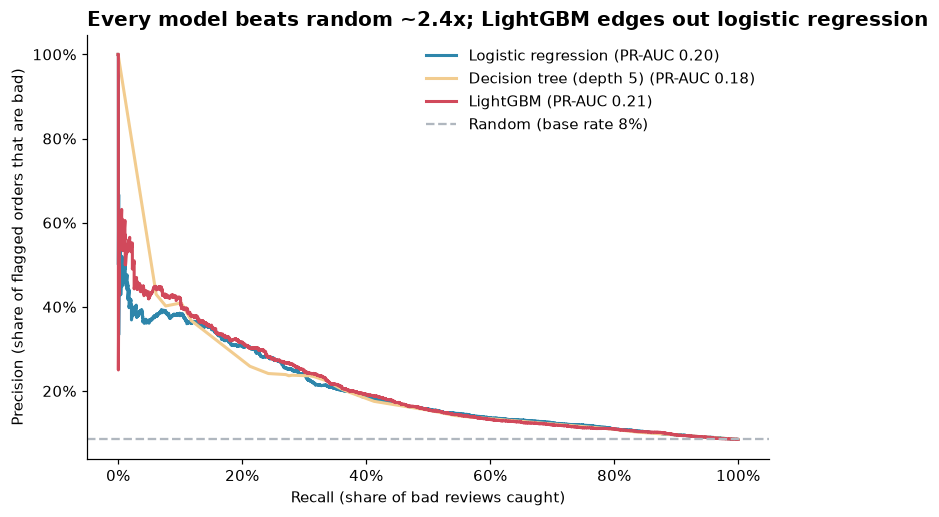

In [9]:
colors = {"Dummy (base rate)": GREY, "Logistic regression": BLUE,
          "Decision tree (depth 5)": SAND, "LightGBM": RED}

fig, ax = plt.subplots(figsize=(8, 5))
for name, proba in test_proba.items():
    if name.startswith("Dummy"):
        continue
    p, r, _ = precision_recall_curve(y_test, proba)
    ax.plot(r, p, color=colors[name], lw=2,
            label=f"{name} (PR-AUC {average_precision_score(y_test, proba):.2f})")
ax.axhline(y_test.mean(), color=GREY, ls="--", label=f"Random (base rate {y_test.mean():.0%})")
ax.set_xlabel("Recall (share of bad reviews caught)")
ax.set_ylabel("Precision (share of flagged orders that are bad)")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Every model beats random ~2.4x; LightGBM edges out logistic regression")
ax.legend(frameon=False)
save(fig, "12_precision_recall_curves")
plt.show()

### Business view: who should customer service contact?

The **capture curve** sorts orders from highest to lowest predicted risk and shows what share of all bad reviews we reach by contacting the top X% of orders.

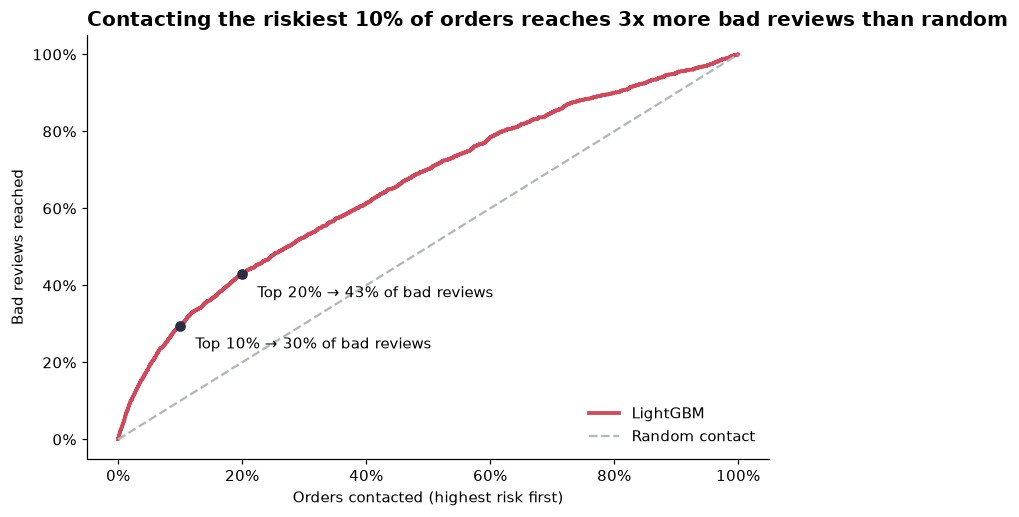

In [10]:
proba = test_proba["LightGBM"]
order = np.argsort(-proba)
captured = np.cumsum(y_test[order]) / y_test.sum()
contacted = np.arange(1, len(y_test) + 1) / len(y_test)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(contacted, captured, color=RED, lw=2.5, label="LightGBM")
ax.plot([0, 1], [0, 1], color=GREY, ls="--", label="Random contact")
for frac in [0.10, 0.20]:
    k = int(len(y_test) * frac) - 1
    ax.scatter(contacted[k], captured[k], color=DARK, zorder=3)
    ax.annotate(f"Top {frac:.0%} → {captured[k]:.0%} of bad reviews",
                (contacted[k], captured[k]), xytext=(10, -15), textcoords="offset points")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_xlabel("Orders contacted (highest risk first)")
ax.set_ylabel("Bad reviews reached")
ax.set_title("Contacting the riskiest 10% of orders reaches 3x more bad reviews than random")
ax.legend(frameon=False, loc="lower right")
save(fig, "13_capture_curve")
plt.show()

### Choosing a decision threshold

The model outputs a probability; the team needs a yes/no. We pick the threshold that maximises F1 **on validation**, then check it on test.

In [11]:
p_val = lgbm.predict_proba(X_valid)[:, 1]
prec, rec, thr = precision_recall_curve(y_valid, p_val)
f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
threshold = thr[np.argmax(f1)]

pred = (proba >= threshold).astype(int)
cm = pd.DataFrame(confusion_matrix(y_test, pred),
                  index=["Actual: good", "Actual: bad"], columns=["Predicted: good", "Predicted: bad"])
print(f"Threshold (chosen on validation): {threshold:.3f}")
print(f"Test → precision {precision_score(y_test, pred):.1%}, recall {recall_score(y_test, pred):.1%}, "
      f"F1 {f1_score(y_test, pred):.3f}, flagged {pred.mean():.1%} of orders")
cm

Threshold (chosen on validation): 0.132
Test → precision 21.6%, recall 34.9%, F1 0.267, flagged 13.7% of orders


,Predicted: good,Predicted: bad
Actual: good,19811,2639
Actual: bad,1355,728


## 5. What drives the predictions?

### The decision tree (readable rules)

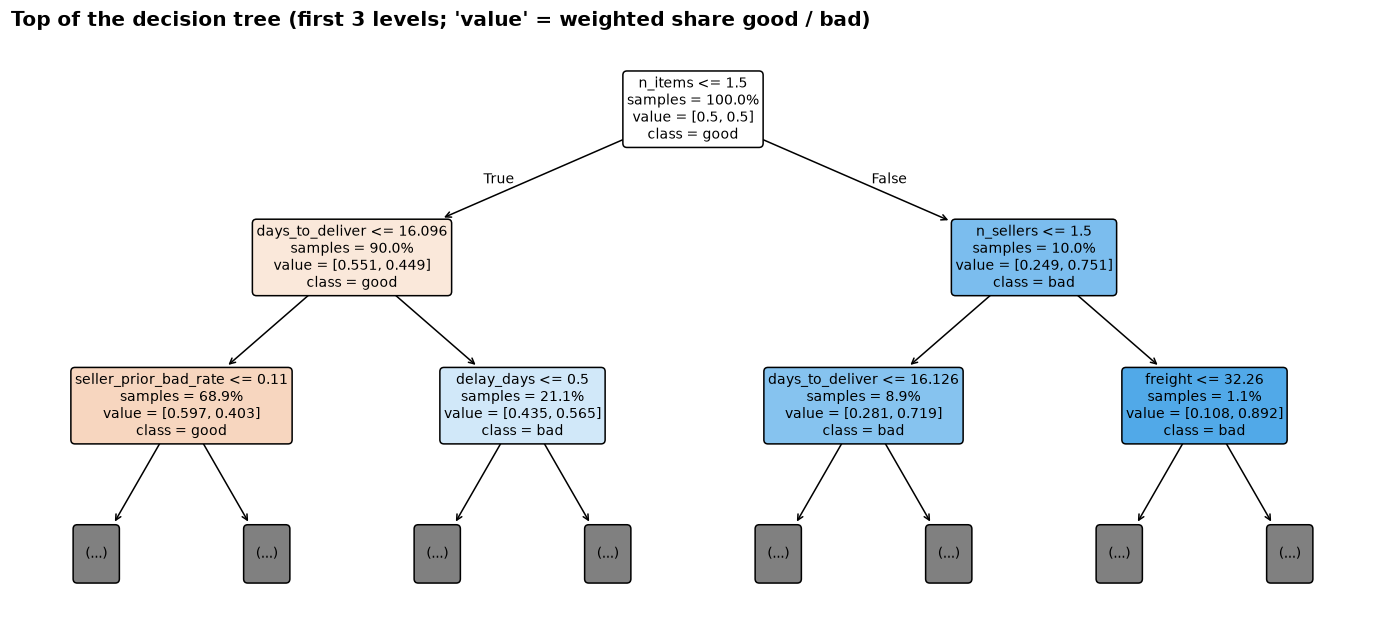

In [12]:
tree = fitted["Decision tree (depth 5)"]
feature_names = [n.split("__", 1)[1] for n in tree.named_steps["prep"].get_feature_names_out()]

fig, ax = plt.subplots(figsize=(16, 7))
plot_tree(tree.named_steps["clf"], max_depth=2, feature_names=feature_names,
          class_names=["good", "bad"], filled=True, impurity=False, proportion=True,
          rounded=True, fontsize=9, ax=ax)
ax.set_title("Top of the decision tree (first 3 levels; 'value' = weighted share good / bad)")
save(fig, "14_decision_tree")
plt.show()

### SHAP values for LightGBM

SHAP splits each prediction into contributions from each feature. In the plot, every dot is an order: position = how much that feature pushed the risk up (right) or down (left); colour = the feature's value (red = high, blue = low). Categorical features have no natural high/low, so their colour is not meaningful.

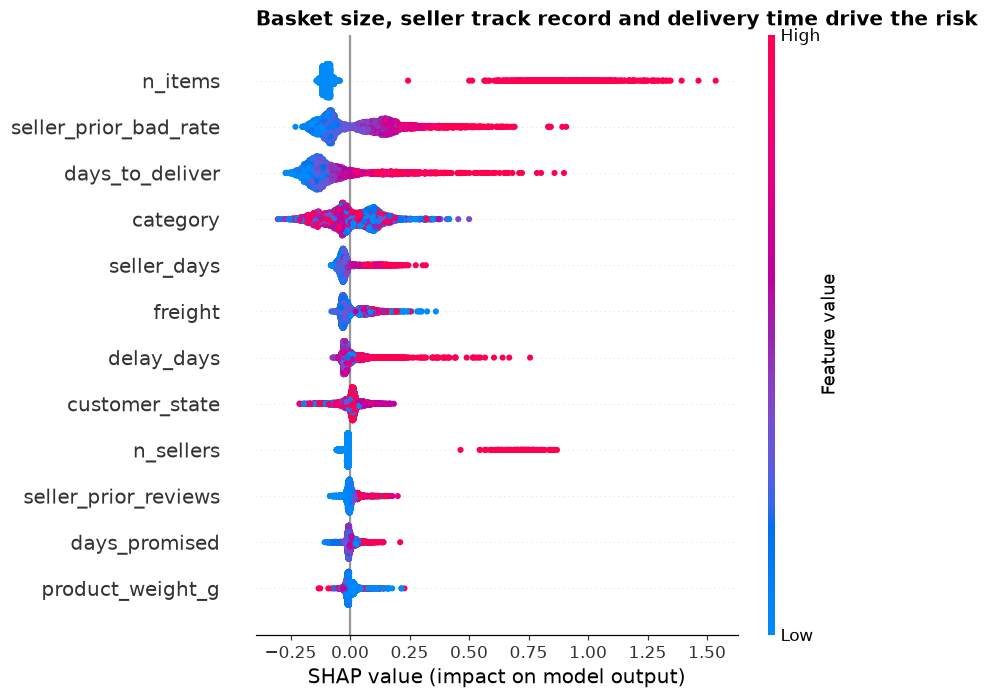

,feature,mean_abs_shap
0,n_items,0.1791
1,seller_prior_bad_rate,0.1373
2,days_to_deliver,0.1312
3,category,0.0873
4,seller_days,0.0408
5,freight,0.0402
6,delay_days,0.0333
7,customer_state,0.0288
8,n_sellers,0.0246
9,seller_prior_reviews,0.0158


In [13]:
sample = X_test.sample(5000, random_state=42)
explainer = shap.TreeExplainer(lgbm)
shap_values = explainer.shap_values(sample)
if isinstance(shap_values, list):      # older shap versions return one array per class
    shap_values = shap_values[1]

display_sample = sample.copy()
for col in CATEGORICAL_FEATURES:       # colour needs numbers; categories become codes
    display_sample[col] = display_sample[col].cat.codes

shap.summary_plot(shap_values, display_sample, max_display=12, show=False)
fig = plt.gcf()
fig.axes[0].set_title("Basket size, seller track record and delivery time drive the risk",
                      loc="left", fontweight="bold")
save(fig, "15_shap_summary")
plt.show()

importance = (
    pd.DataFrame({"feature": FEATURES, "mean_abs_shap": np.abs(shap_values).mean(axis=0)})
    .sort_values("mean_abs_shap", ascending=False)
    .reset_index(drop=True)
)
importance.head(12).round(4)

### A finding the model surfaced: multi-item and multi-seller orders

SHAP ranks `n_items` first, ahead of delivery time. Let us check it directly in the data.

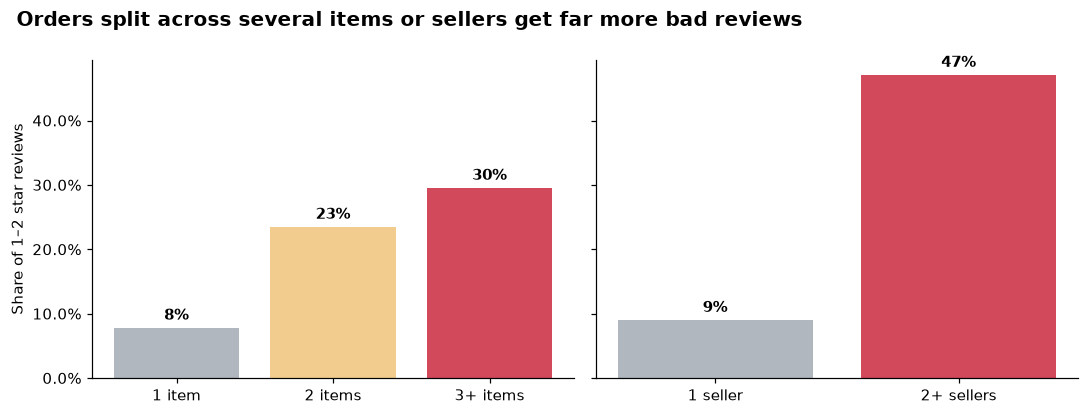

Multi-seller orders delivered ON TIME still get 47% bad reviews


,orders,bad_review_rate
1 item,81463,0.078
2 items,7006,0.235
3+ items,2121,0.295
1 seller,89347,0.090
2+ sellers,1243,0.471


In [14]:
basket = df.assign(
    items=pd.cut(df["n_items"], [0, 1, 2, np.inf], labels=["1 item", "2 items", "3+ items"]),
    sellers=np.where(df["n_sellers"] >= 2, "2+ sellers", "1 seller"),
)
by_items = basket.groupby("items", observed=True)[TARGET].agg(orders="size", bad_review_rate="mean")
by_sellers = basket.groupby("sellers")[TARGET].agg(orders="size", bad_review_rate="mean")
on_time_multi = basket.loc[(basket["sellers"] == "2+ sellers") & (basket["is_late"] == 0), TARGET].mean()

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, tbl, cols in [(axes[0], by_items, [GREY, SAND, RED]), (axes[1], by_sellers, [GREY, RED])]:
    bars = ax.bar(tbl.index.astype(str), tbl["bad_review_rate"], color=cols)
    ax.bar_label(bars, labels=[f"{v:.0%}" for v in tbl["bad_review_rate"]], padding=3, fontweight="bold")
axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
axes[0].set_ylabel("Share of 1–2 star reviews")
fig.suptitle("Orders split across several items or sellers get far more bad reviews",
             x=0.02, ha="left", fontweight="bold", fontsize=13)
fig.tight_layout()
save(fig, "16_bad_reviews_by_basket")
plt.show()

print(f"Multi-seller orders delivered ON TIME still get {on_time_multi:.0%} bad reviews")
pd.concat([by_items, by_sellers]).round(3)

**Hypothesis:** items from different sellers ship separately. The order is marked "delivered" when one parcel arrives, so the customer may review while still missing products. Phase 5 (review text) can test this by looking for complaints like *"não recebi"* ("I did not receive").

## 6. Save artefacts for the dashboard

In [15]:
joblib.dump(lgbm, MODEL_DIR / "bad_review_lgbm.joblib")

test_out = test[["order_id", "purchase_ts"]].assign(is_bad_review=y_test, risk=proba)
test_out.to_parquet(DATA_DIR / "test_predictions.parquet", index=False)
importance.to_parquet(DATA_DIR / "shap_importance.parquet", index=False)
test_scores.reset_index().to_parquet(DATA_DIR / "model_scores.parquet", index=False)
print("Saved model, test predictions, SHAP importance and model scores")

Saved model, test predictions, SHAP importance and model scores


## Key findings

1. **The model is useful but modest — and that is an honest result.** On the unseen test period (May–Aug 2018) LightGBM reaches PR-AUC **0.21** vs a random baseline of **0.085** (≈2.4x), ROC-AUC 0.67. Contacting the riskiest **10%** of orders reaches **30%** of all bad reviews (lift ≈ **3x**); the riskiest 20% reach 43%.
2. **Simple models are almost as good.** Logistic regression (PR-AUC 0.20) and a depth-5 decision tree (0.18) are close to LightGBM. If the business values explainability, logistic regression is a defensible choice.
3. **Removing reviews written before delivery made the task harder — on purpose.** Those reviews were 95% late and 73% bad; keeping them would inflate the scores with information that does not exist at prediction time (leakage).
4. **Top drivers (SHAP): basket size, the seller's past bad-review rate, and delivery time.** The seller-history feature adds a small but real gain (validation PR-AUC 0.275 → 0.282).
5. **New business finding: split orders.** Orders with 2+ sellers get **47%** bad reviews **even when delivered on time** (vs 9% for single-seller orders); 3+ item orders get 30%. Likely cause: items ship separately and the order is marked delivered before everything arrives.
6. **Validation → test drop** (PR-AUC 0.28 → 0.21) comes partly from a lower bad-review rate in the test months (10.4% → 8.5%); the lift stays stable at ~3x, which is what matters for prioritising contacts.

**Why the ceiling is low:** many bad reviews come from things not in the structured data (product quality, wrong item, damaged packaging). Phase 5 uses the review **text** to see what customers actually complain about.

**Business recommendations**
- Use the risk score to **prioritise proactive customer-service contacts** after delivery (top 10–20% of orders).
- **Fix split shipments:** show customers clearly when an order arrives in several parcels, and only mark an order as delivered when every parcel has arrived.
- **Monitor sellers** with a high past bad-review rate.